Osserva attentamente questa immagine: probabilmente ne hai viste di simili molte volte. Cosa noti? Cosa ti chiedi?

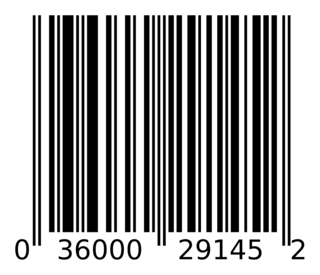

È legittimo domandarsi se esiste una qualche relazione tra i numeri e le barre.
In realtà, sono semplicemente due modi diversi per _rappresentare_ lo stesso dato.

Esistono numerosi standard mondiali per _identificare univocamente_ i prodotti in commercio.
Uno di questi standard è il [GTIN](https://it.wikipedia.org/wiki/Global_Trade_Item_Number).

Ne esistono diverse varianti, tra cui il GTIN-12 è tra le più diffuse:
senza troppa sorpresa, prevede di identificare ogni prodotto univocamente con un numero a 12 cifre
(che a sua volta ha una certa struttura, con alcune cifre che identificano il produttore e altre il prodotto specifico, ma qui non ci addentriamo nei dettagli).

## Codici a barre nel formato UPC

Il codice a barre mostrato sopra contiene in effetti il GTIN-12 _due volte_:
nella parte inferiore le cifre sono scritte in modo che siano facilmente leggibili da un _umano_ ("human-readable"),
mentre nella parte superiore sono codificate con un alternarsi di barre e spazi in modo da essere facilmente leggibili da una _macchina_ ("machine-readable").

Il formato di codifica delle barre mostrato sopra usa lo standard [UPC](https://it.wikipedia.org/wiki/Universal_Product_Code) (Universal Product Code),
nella sua variante UPC-A,
che è appunto in grado di rappresentare un numero a 12 cifre.

Questo formato definisce semplicemente una struttura composta da 95 _moduli_.
Un modulo è ciascuna delle strisce verticali, che sono separate da una linea rossa nella figura seguente,
riempita di nero (quello che colloquialmente chiamiamo "barra") o bianco (lo "spazio").

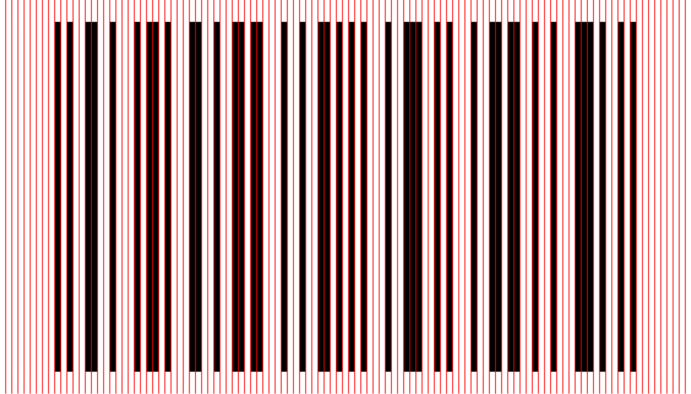

Possiamo raggruppare in moduli nei seguenti gruppi:

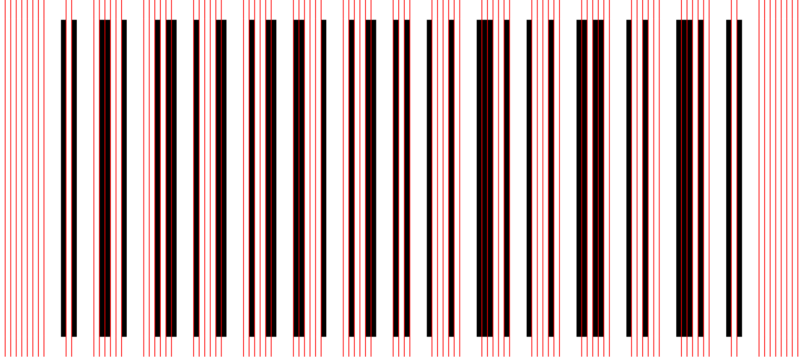

- agli estremi sinistro e destro, due gruppi detti "quiet" composti ciascuno da 9 moduli di spazio
- appena più all'interno, rispettivamente un gruppo "start" a sinistra e un gruppo "end" a destra composti ciascuno dalla sequenza barra-spazio-barra
- un gruppo al centro composto da 5 moduli, spazio-barra-spazio-barra-spazio
- i rimanenti 12 gruppi (6 a sinistra e 6 a destra rispetto al gruppo centrale) sono composti ciascuno da 7 moduli e codificano in sequenza le cifre del numero che vogliamo rappresentare

Prima di addentrarci nella codifica delle singole cifre, prova a creare il gruppo "start" semplicemente mettendo tre rettangoli uno <API>accanto</API> all'altro:

In [ ]:
from pytamaro.it import rettangolo, accanto, bianco, nero, visualizza_grafica, Grafica

def modulo(barra: bool) -> Grafica:
    # TODO: ritorna un rettangolo nero se `barra` è `True`, altrimenti bianco

start = # TODO: affianca tre moduli per creare il gruppo che segna l'inizio

visualizza_grafica(start)

## Codifica delle cifre

Per semplicità, iniziamo a codificare le prime sei cifre (per intenderci, quelle di sinistra, comprese tra il gruppo iniziale e quello centrale).

Ogni cifra è rappresentata usando 7 moduli.
La cifra 0, ad esempio, è rappresentata con la sequenza spazio-spazio-spazio-barra-barra-spazio-barra.
Possiamo per comodità identificare lo spazio con il valore booleano `False` e la barra con il valore `True`.
Consultando lo standard, possiamo creare una lista dove l'elemento in posizione `i` indica la codifica della cifra `i`,
rappresentata con una lista di 7 valori booleani.

Implementa una funzione che crei la grafica corrispondente alla cifra data,
affiancando opportunamente 7 moduli
(ricorda che puoi chiamare la funzione `modulo` definita sopra).

Non preoccuparti per ora di gestire il caso in cui `sinistra` sia `False`:
ci occuperemo a breve della parte destra.

In [ ]:
CODIFICA_CIFRA = [
    [False, False, False, True, True, False, True],  # 0
    [False, False, True, True, False, False, True],  # 1
    [False, False, True, False, False, True, True],  # 2
    [False, True, True, True, True, False, True],    # 3
    [False, True, False, False, False, True, True],  # 4
    [False, True, True, False, False, False, True],  # 5
    [False, True, False, True, True, True, True],    # 6
    [False, True, True, True, False, True, True],    # 7 
    [False, True, True, False, True, True, True],    # 8
    [False, False, False, True, False, True, True]   # 9
]

def grafica_per_cifra(cifra: int, sinistra: bool) -> Grafica:
    # TODO

visualizza_grafica(grafica_per_cifra(0, True))

Le seconde sei cifre, a destra della parte centrale, sono codificate invertendo i ruoli di barra e spazio:
la cifra 0, ad esempio, è rappresentata con la sequenza barra-barra-barra-spazio-spazio-barra-spazio
(esattamente l'opposto della codifica per la parte sinistra).

Estendi l'implementazione della funzione che hai appena definito per gestire anche il caso in cui `sinistra` sia `False`.

## Mettiamo insieme i pezzi

Possiamo ora creare l'intero codice a barre, affiancando i gruppi di moduli come descritto sopra nell'elenco puntato.

Puoi verificare che il codice a barre "funziona davvero" inquadrandolo con il tuo smartphone e un'applicazione che legga i codici a barre
(ne puoi trovare di gratuite sui vari store per le applicazioni). 

In [ ]:
def codice(cifre: list[int]) -> Grafica:
    """
    Crea un codice a barre in formato UPC-A affiancando:
    - un gruppo quiet
    - un gruppo start
    - le prime sei cifre a sinistra
    - un gruppo centrale
    - le ultime sei cifre a destra
    - un gruppo end
    - un gruppo quiet
    """
    # TODO


# Costruisce e visualizza il codice a barre per il numero 761081829658
visualizza_grafica(codice([7, 6, 1, 0, 8, 1, 8, 2, 9, 6, 5, 8]))